<a href="https://colab.research.google.com/github/Ankitajena12/Handwritten-Digit-recognition-using-CNN/blob/main/DeepLearningGroupProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Setup
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import time

print("TF version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

tf.random.set_seed(42)
np.random.seed(42)

# Upload the 4 idx files from Kaggle (train-images, train-labels, t10k-images, t10k-labels)
from google.colab import files
uploaded = files.upload()   # select all 4 .idx files when prompted

TF version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Saving train-images.idx3-ubyte to train-images.idx3-ubyte
Saving train-labels.idx1-ubyte to train-labels.idx1-ubyte
Saving t10k-images.idx3-ubyte to t10k-images.idx3-ubyte
Saving t10k-labels.idx1-ubyte to t10k-labels.idx1-ubyte


In [ ]:
# Cell 2: Parse IDX format (no external library needed)
import struct

def load_idx_images(path):
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack('>IIII', f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(n, rows, cols)

def load_idx_labels(path):
    with open(path, 'rb') as f:
        magic, n = struct.unpack('>II', f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train_full = load_idx_images('train-images.idx3-ubyte')
y_train_full = load_idx_labels('train-labels.idx1-ubyte')
X_test = load_idx_images('t10k-images.idx3-ubyte')
y_test = load_idx_labels('t10k-labels.idx1-ubyte')

print("Train:", X_train_full.shape, y_train_full.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)


Train: (54000, 28, 28, 1, 1) Val: (6000, 28, 28, 1, 1) Test: (10000, 28, 28, 1, 1)


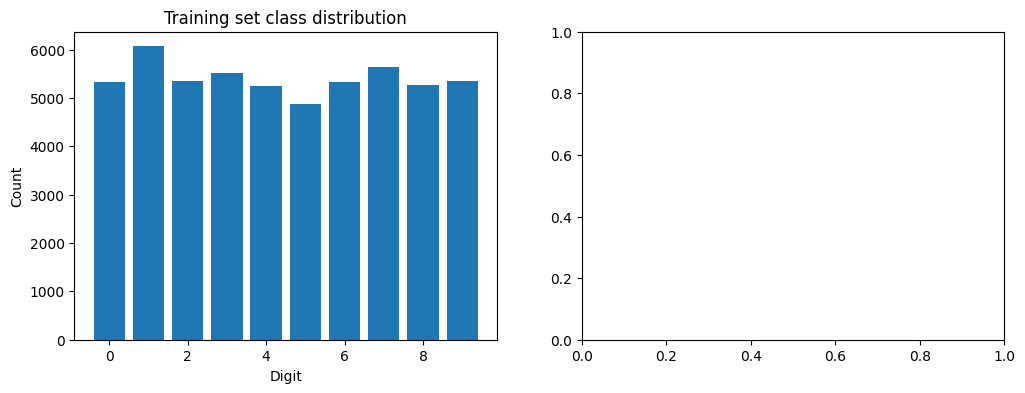

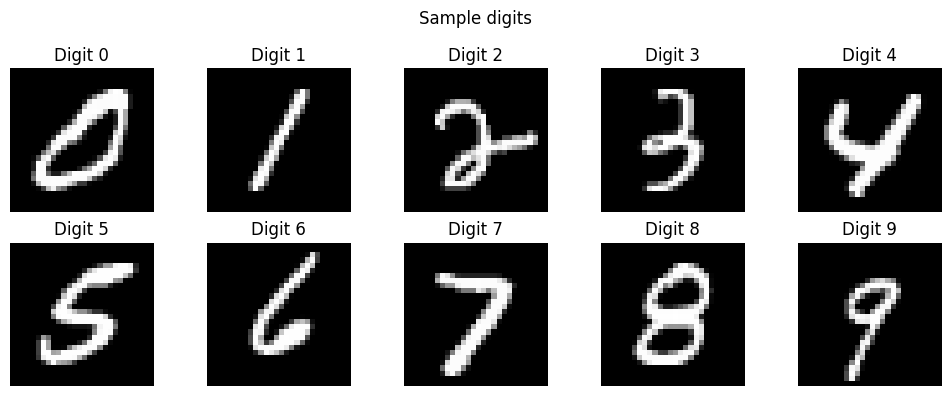

In [ ]:
# Cell 3: Preprocess, split, visualize
# Normalize to [0,1] and add channel dimension
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
X_train_full = X_train_full[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Stratified 90/10 train/val split -> 54000 train, 6000 val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10,
    stratify=y_train_full, random_state=42
)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# Class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(*np.unique(y_train, return_counts=True))
axes[0].set_title("Training set class distribution")
axes[0].set_xlabel("Digit"); axes[0].set_ylabel("Count")

# Sample digits
fig2, axs = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axs.flat):
    idx = np.where(y_train == i)[0][0]
    ax.imshow(X_train[idx].squeeze(), cmap='gray')
    ax.set_title(f"Digit {i}"); ax.axis('off')
plt.suptitle("Sample digits")
plt.tight_layout()
plt.savefig('sample_digits.png')
plt.show()

In [ ]:
# Cell 4: Model builders
def build_mlp():
    inp = keras.Input((28, 28, 1))
    x = layers.Flatten()(inp)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dense(128, activation='relu')(x)
    out = layers.Dense(10, activation='softmax')(x)
    return keras.Model(inp, out, name="MLP")

def build_lenet():
    inp = keras.Input((28, 28, 1))
    x = layers.Conv2D(6, 5, padding='same', activation='tanh')(inp)
    x = layers.AveragePooling2D(2)(x)
    x = layers.Conv2D(16, 5, padding='valid', activation='tanh')(x)
    x = layers.AveragePooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(120, activation='tanh')(x)
    x = layers.Dense(84, activation='tanh')(x)
    out = layers.Dense(10, activation='softmax')(x)
    return keras.Model(inp, out, name="LeNet")

def build_cnn(k=3, stride=1, padding="same", bn=True, pool=True, filters=(32, 64)):
    inp = keras.Input((28, 28, 1)); x = inp
    for f in filters:
        x = layers.Conv2D(f, k, strides=stride, padding=padding, use_bias=not bn)(x)
        if bn: x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        if pool: x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inp, out, name="Proposed_CNN")

# Sanity check
build_mlp().summary()
build_lenet().summary()
build_cnn().summary()

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Model: "LeNet"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,930 (1.61 MB)

 Trainable params: 421,738 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
# Cell 5: Train MLP, LeNet, Proposed CNN
def train_model(model, epochs=20, batch_size=128):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                         restore_best_weights=True)
    t0 = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=epochs, batch_size=batch_size,
                         callbacks=[es], verbose=2)
    train_time = time.time() - t0
    return history, train_time

results = {}   # will hold metrics for the comparison table
histories = {}

mlp = build_mlp()
histories['MLP'], t_mlp = train_model(mlp)

lenet = build_lenet()
histories['LeNet'], t_lenet = train_model(lenet)

cnn = build_cnn()
histories['Proposed_CNN'], t_cnn = train_model(cnn)

train_times = {'MLP': t_mlp, 'LeNet': t_lenet, 'Proposed_CNN': t_cnn}
models = {'MLP': mlp, 'LeNet': lenet, 'Proposed_CNN': cnn}

Epoch 1/20
422/422 - 6s - 14ms/step - accuracy: 0.9194 - loss: 0.2834 - val_accuracy: 0.9583 - val_loss: 0.1500
Epoch 2/20
422/422 - 1s - 3ms/step - accuracy: 0.9686 - loss: 0.1057 - val_accuracy: 0.9657 - val_loss: 0.1141
Epoch 3/20
422/422 - 1s - 3ms/step - accuracy: 0.9799 - loss: 0.0675 - val_accuracy: 0.9722 - val_loss: 0.0989
Epoch 4/20
422/422 - 1s - 3ms/step - accuracy: 0.9858 - loss: 0.0481 - val_accuracy: 0.9732 - val_loss: 0.0932
Epoch 5/20
422/422 - 1s - 3ms/step - accuracy: 0.9896 - loss: 0.0351 - val_accuracy: 0.9740 - val_loss: 0.0891
Epoch 6/20
422/422 - 1s - 3ms/step - accuracy: 0.9917 - loss: 0.0284 - val_accuracy: 0.9765 - val_loss: 0.0892
Epoch 7/20
422/422 - 1s - 3ms/step - accuracy: 0.9928 - loss: 0.0221 - val_accuracy: 0.9725 - val_loss: 0.1136
Epoch 8/20
422/422 - 1s - 3ms/step - accuracy: 0.9954 - loss: 0.0160 - val_accuracy: 0.9732 - val_loss: 0.1142
Epoch 1/20
422/422 - 9s - 21ms/step - accuracy: 0.9032 - loss: 0.3386 - val_accuracy: 0.9488 - val_loss: 0.1691

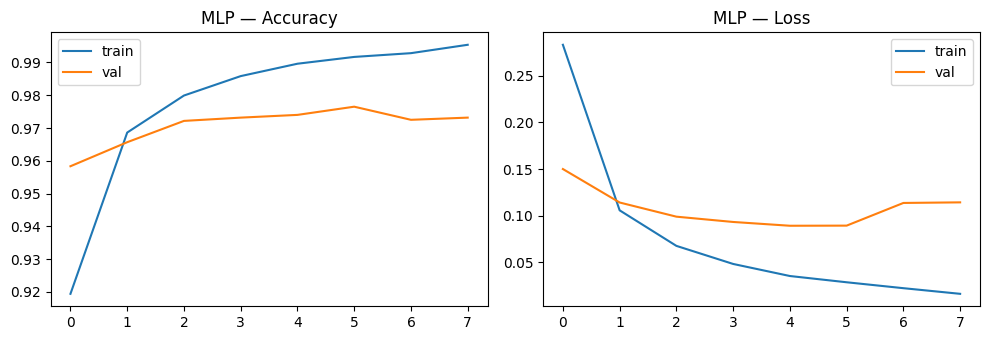

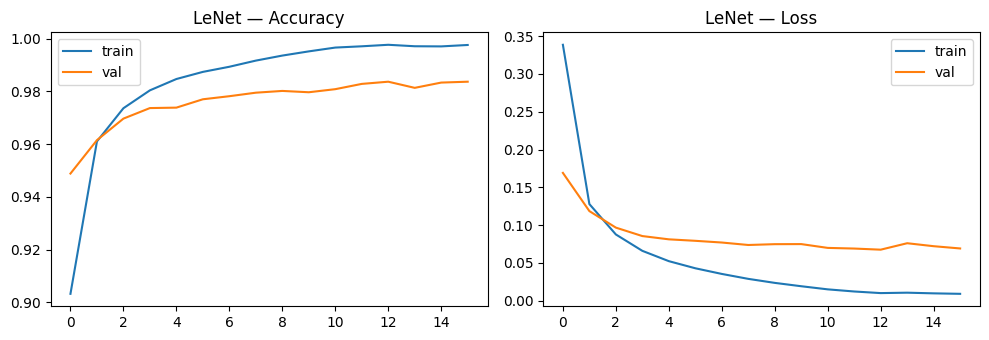

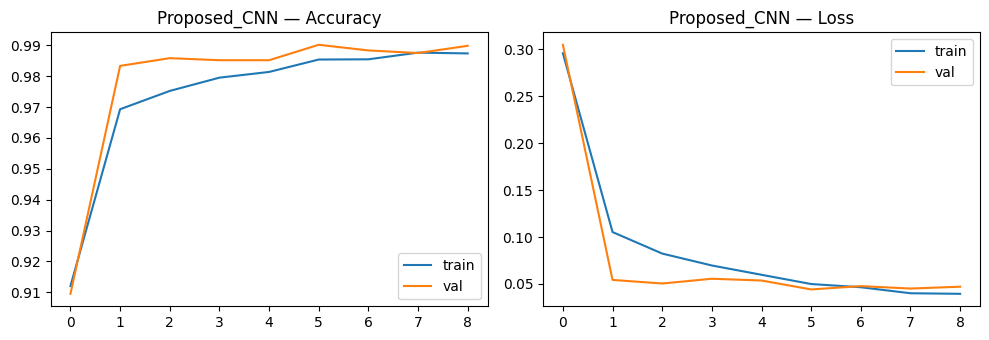

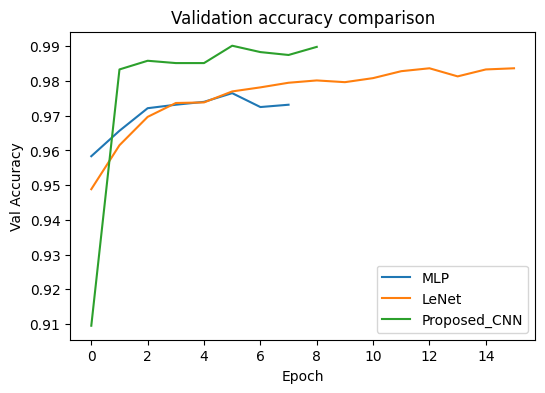

In [ ]:
# Cell 6: Plot curves for each model
for name, hist in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(hist.history['accuracy'], label='train')
    axes[0].plot(hist.history['val_accuracy'], label='val')
    axes[0].set_title(f"{name} — Accuracy"); axes[0].legend()
    axes[1].plot(hist.history['loss'], label='train')
    axes[1].plot(hist.history['val_loss'], label='val')
    axes[1].set_title(f"{name} — Loss"); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'curves_{name.lower()}.png')
    plt.show()

# Combined val accuracy comparison
plt.figure(figsize=(6,4))
for name, hist in histories.items():
    plt.plot(hist.history['val_accuracy'], label=name)
plt.title("Validation accuracy comparison")
plt.xlabel("Epoch"); plt.ylabel("Val Accuracy"); plt.legend()
plt.savefig('val_acc_comparison.png')
plt.show()

In [ ]:
# Cell 7: Test-set evaluation and comparison.csv
import pandas as pd

rows = []
for name, model in models.items():
    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    report = classification_report(y_test, y_pred, output_dict=True)
    n_params = model.count_params()
    rows.append({
        'Model': name,
        'Test Accuracy': report['accuracy'],
        'Macro Precision': report['macro avg']['precision'],
        'Macro Recall': report['macro avg']['recall'],
        'Macro F1': report['macro avg']['f1-score'],
        'Params': n_params,
        'Train Time (s)': round(train_times[name], 1)
    })
    if name == 'Proposed_CNN':
        y_pred_cnn = y_pred   # save for confusion matrix later

comparison_df = pd.DataFrame(rows)
comparison_df.to_csv('comparison.csv', index=False)
print(comparison_df.to_string(index=False))

       Model  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Params  Train Time (s)
         MLP         0.9758         0.975989      0.975451  0.975654  235146            15.0
       LeNet         0.9834         0.983104      0.983342  0.983198   61706            34.5
Proposed_CNN         0.9899         0.989903      0.989838  0.989849  421930            30.0


In [ ]:
# Cell 8: 8 configurations, 5 epochs each
configs = [
    (3, 1, 'same'), (5, 1, 'same'), (7, 1, 'same'),
    (3, 1, 'valid'), (5, 1, 'valid'), (7, 1, 'valid'),
    (3, 2, 'same'), (3, 2, 'valid'),
]

conv_rows = []
for k, s, p in configs:
    keras.utils.set_random_seed(42)
    m = build_cnn(k=k, stride=s, padding=p)
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    m.fit(X_train, y_train, validation_data=(X_val, y_val),
          epochs=5, batch_size=128, verbose=0)
    t = time.time() - t0
    test_loss, test_acc = m.evaluate(X_test, y_test, verbose=0)
    conv1 = [l for l in m.layers if isinstance(l, layers.Conv2D)][0]
    fmap = conv1.output.shape[1:3]
    conv_rows.append({
        'Filter': f'{k}x{k}', 'Stride': s, 'Padding': p,
        'Conv1 Map Size': f'{fmap[0]}x{fmap[1]}',
        'Params': m.count_params(),
        'Test Accuracy': round(test_acc, 4),
        'Train Time (s)': round(t, 1)
    })
    print(conv_rows[-1])

conv_df = pd.DataFrame(conv_rows)
conv_df.to_csv('conv_study.csv', index=False)
print(conv_df.to_string(index=False))

{'Filter': '3x3', 'Stride': 1, 'Padding': 'same', 'Conv1 Map Size': '28x28', 'Params': 421930, 'Test Accuracy': 0.99, 'Train Time (s)': 20.5}
{'Filter': '5x5', 'Stride': 1, 'Padding': 'same', 'Conv1 Map Size': '28x28', 'Params': 455210, 'Test Accuracy': 0.988, 'Train Time (s)': 22.4}
{'Filter': '7x7', 'Stride': 1, 'Padding': 'same', 'Conv1 Map Size': '28x28', 'Params': 505130, 'Test Accuracy': 0.9898, 'Train Time (s)': 25.3}
{'Filter': '3x3', 'Stride': 1, 'Padding': 'valid', 'Conv1 Map Size': '26x26', 'Params': 225322, 'Test Accuracy': 0.9885, 'Train Time (s)': 20.0}
{'Filter': '5x5', 'Stride': 1, 'Padding': 'valid', 'Conv1 Map Size': '24x24', 'Params': 184874, 'Test Accuracy': 0.9908, 'Train Time (s)': 19.2}
{'Filter': '7x7', 'Stride': 1, 'Padding': 'valid', 'Conv1 Map Size': '22x22', 'Params': 136490, 'Test Accuracy': 0.9912, 'Train Time (s)': 19.0}
{'Filter': '3x3', 'Stride': 2, 'Padding': 'same', 'Conv1 Map Size': '14x14', 'Params': 53290, 'Test Accuracy': 0.983, 'Train Time (s)': 

In [ ]:
# Cell 9: 2x2 ablation
abl_rows = []
for bn in [True, False]:
    for pool in [True, False]:
        keras.utils.set_random_seed(42)
        m = build_cnn(bn=bn, pool=pool)
        m.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=5, batch_size=128, verbose=0)
        t = time.time() - t0
        test_loss, test_acc = m.evaluate(X_test, y_test, verbose=0)
        abl_rows.append({
            'BatchNorm': bn, 'MaxPool': pool,
            'Params': m.count_params(),
            'Test Accuracy': round(test_acc, 4),
            'Train Time (s)': round(t, 1)
        })
        print(abl_rows[-1])

abl_df = pd.DataFrame(abl_rows)
abl_df.to_csv('ablation.csv', index=False)
print(abl_df.to_string(index=False))

{'BatchNorm': True, 'MaxPool': True, 'Params': 421930, 'Test Accuracy': 0.9879, 'Train Time (s)': 19.6}
{'BatchNorm': True, 'MaxPool': False, 'Params': 6443050, 'Test Accuracy': 0.9821, 'Train Time (s)': 31.4}
{'BatchNorm': False, 'MaxPool': True, 'Params': 421642, 'Test Accuracy': 0.9912, 'Train Time (s)': 20.9}
{'BatchNorm': False, 'MaxPool': False, 'Params': 6442762, 'Test Accuracy': 0.9883, 'Train Time (s)': 26.2}
 BatchNorm  MaxPool  Params  Test Accuracy  Train Time (s)
      True     True  421930         0.9879            19.6
      True    False 6443050         0.9821            31.4
     False     True  421642         0.9912            20.9
     False    False 6442762         0.9883            26.2


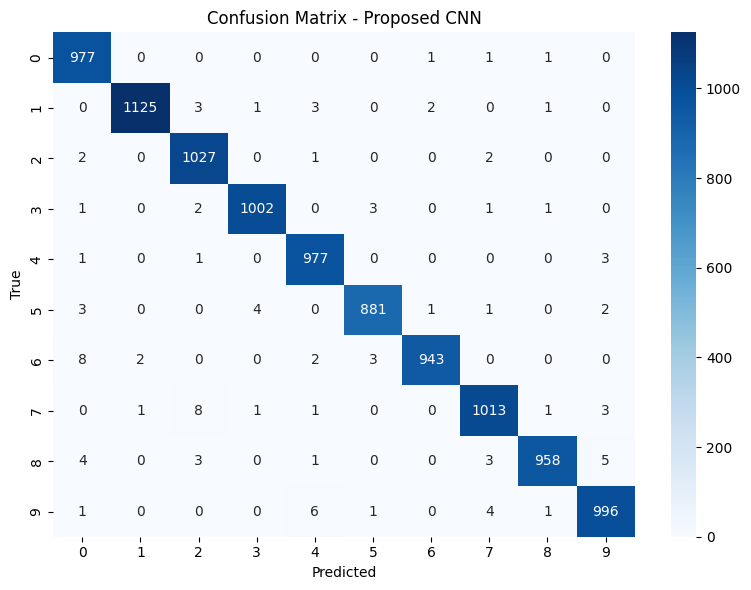

              precision    recall  f1-score   support

           0     0.9799    0.9969    0.9884       980
           1     0.9973    0.9912    0.9943      1135
           2     0.9837    0.9952    0.9894      1032
           3     0.9940    0.9921    0.9931      1010
           4     0.9859    0.9949    0.9904       982
           5     0.9921    0.9877    0.9899       892
           6     0.9958    0.9843    0.9900       958
           7     0.9883    0.9854    0.9868      1028
           8     0.9948    0.9836    0.9892       974
           9     0.9871    0.9871    0.9871      1009

    accuracy                         0.9899     10000
   macro avg     0.9899    0.9898    0.9898     10000
weighted avg     0.9899    0.9899    0.9899     10000

Total errors: 101 of 10000


In [ ]:
# Cell 10: Confusion matrix
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix - Proposed CNN')
plt.tight_layout()
plt.savefig('confusion_matrix_cnn.png', dpi=150)
plt.show()

report_df = pd.DataFrame(classification_report(y_test, y_pred_cnn, output_dict=True)).T
report_df.to_csv('classification_report_cnn.csv')
print(classification_report(y_test, y_pred_cnn, digits=4))
print("Total errors:", (y_pred_cnn != y_test).sum(), "of", len(y_test))

In [ ]:
# Cell 11: Top confused pairs
pairs = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            pairs.append({'True': i, 'Predicted': j, 'Count': int(cm[i, j])})
pairs_df = pd.DataFrame(pairs).sort_values('Count', ascending=False).head(10)
pairs_df.to_csv('top_confused_pairs.csv', index=False)
print(pairs_df.to_string(index=False))

# Unordered pairs (A<->B combined)
combined = {}
for i in range(10):
    for j in range(i + 1, 10):
        combined[(i, j)] = int(cm[i, j] + cm[j, i])
print("\nTop combined pairs (A<->B):")
for pair, c in sorted(combined.items(), key=lambda x: -x[1])[:5]:
    print(pair, c)

 True  Predicted  Count
    7          2      8
    6          0      8
    9          4      6
    8          9      5
    5          3      4
    9          7      4
    8          0      4
    3          5      3
    1          2      3
    1          4      3

Top combined pairs (A<->B):
(2, 7) 10
(0, 6) 9
(4, 9) 9
(3, 5) 7
(7, 9) 7


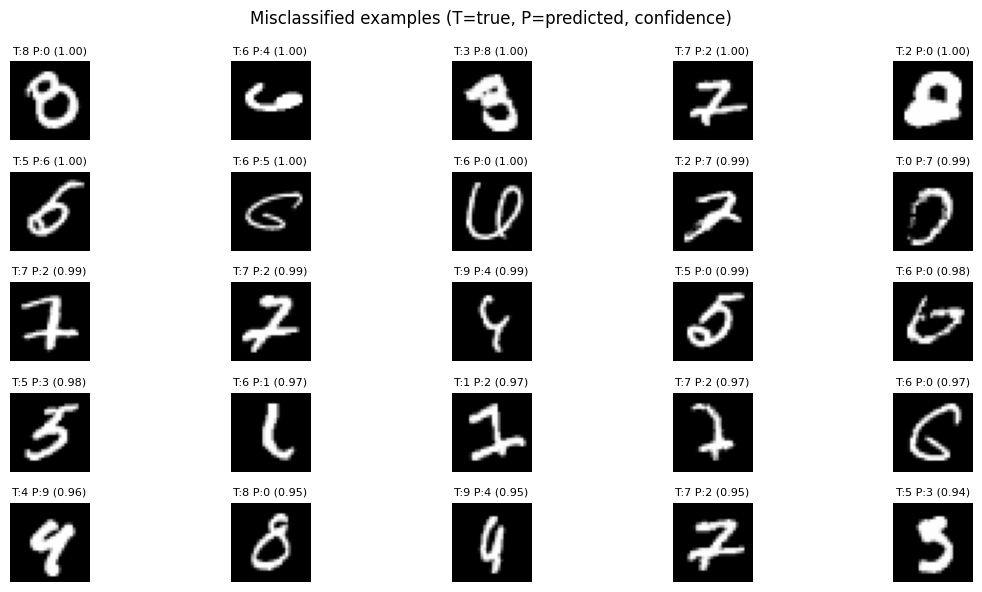

Mean confidence on mistakes: 0.768
Mean confidence on correct : 0.996


In [ ]:
# Cell 12: Misclassified images
probs = cnn.predict(X_test, verbose=0)
wrong = np.where(y_pred_cnn != y_test)[0]
conf = probs[wrong, y_pred_cnn[wrong]]
order = wrong[np.argsort(-conf)][:25]   # most confident mistakes first

plt.figure(figsize=(12, 6))
for n, idx in enumerate(order):
    plt.subplot(5, 5, n + 1)
    plt.imshow(X_test[idx].squeeze(), cmap='gray')
    plt.title(f"T:{y_test[idx]} P:{y_pred_cnn[idx]} ({probs[idx, y_pred_cnn[idx]]:.2f})", fontsize=8)
    plt.axis('off')
plt.suptitle("Misclassified examples (T=true, P=predicted, confidence)")
plt.tight_layout()
plt.savefig('misclassified.png', dpi=150)
plt.show()

print("Mean confidence on mistakes:", round(float(conf.mean()), 3))
print("Mean confidence on correct :", round(float(probs[np.where(y_pred_cnn == y_test)[0]].max(axis=1).mean()), 3))

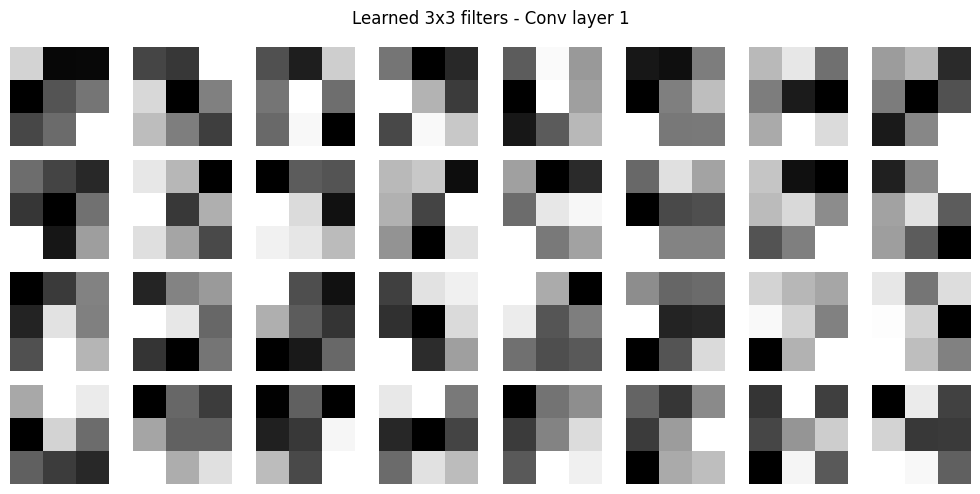

In [ ]:
# Cell 13: First conv layer filters
conv_layers = [l for l in cnn.layers if isinstance(l, layers.Conv2D)]
W = conv_layers[0].get_weights()[0]   # shape (3, 3, 1, 32)
n = W.shape[-1]

plt.figure(figsize=(10, 5))
for i in range(n):
    plt.subplot(4, 8, i + 1)
    plt.imshow(W[:, :, 0, i], cmap='gray')
    plt.axis('off')
plt.suptitle("Learned 3x3 filters - Conv layer 1")
plt.tight_layout()
plt.savefig('filters_conv1.png', dpi=150)
plt.show()

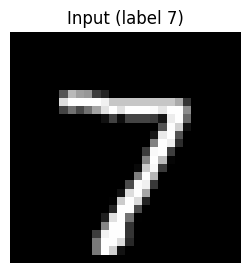

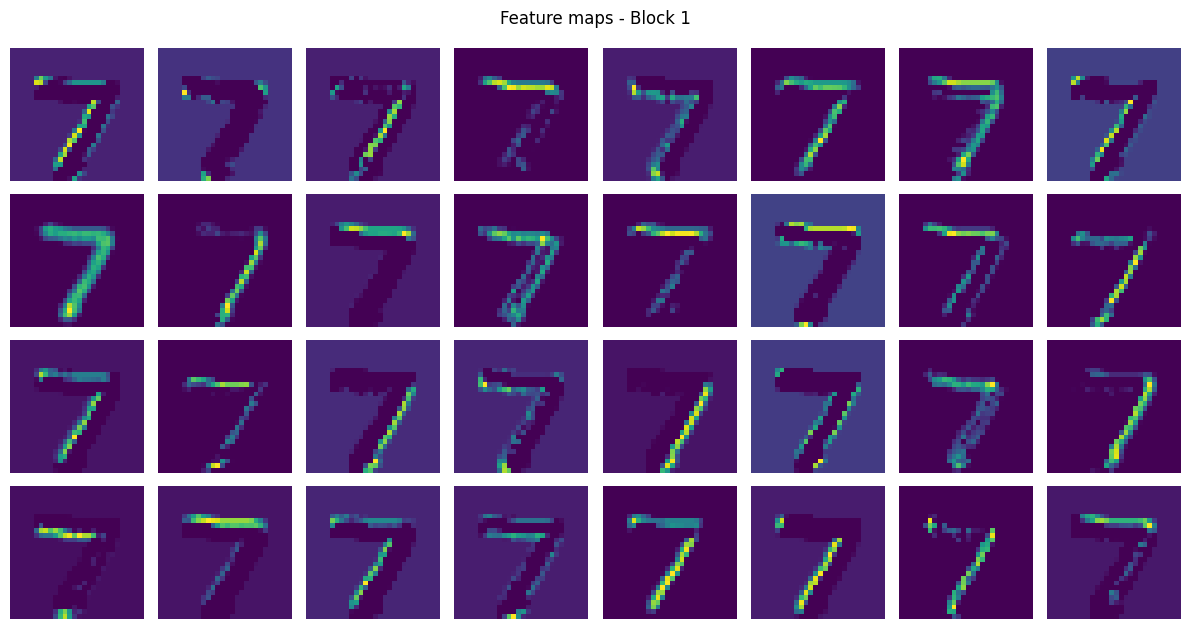

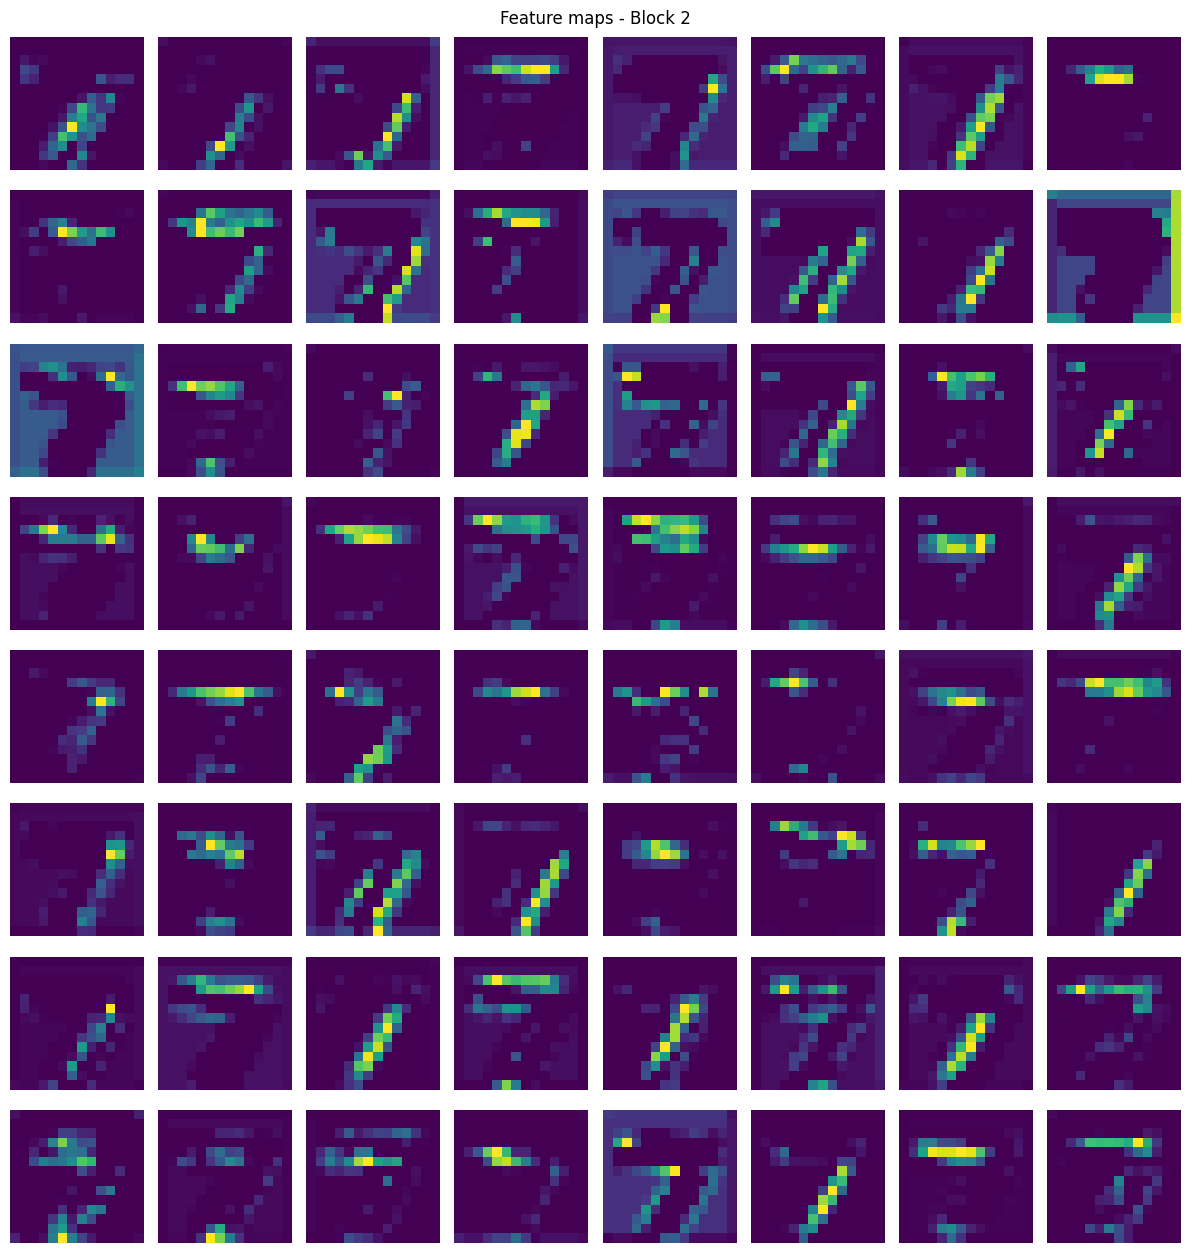

In [ ]:
# Cell 14: Feature maps
act_layers = [l for l in cnn.layers if isinstance(l, layers.Activation)][:2]
fmap_model = keras.Model(cnn.input, [l.output for l in act_layers])

sample = X_test[0:1]   # first test image
outputs = fmap_model.predict(sample, verbose=0)

plt.figure(figsize=(3, 3))
plt.imshow(sample[0].squeeze(), cmap='gray')
plt.title(f"Input (label {y_test[0]})"); plt.axis('off')
plt.show()

for b, fm in enumerate(outputs, start=1):
    n = fm.shape[-1]
    cols = 8
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(12, 1.6 * rows))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(fm[0, :, :, i], cmap='viridis')
        plt.axis('off')
    plt.suptitle(f"Feature maps - Block {b}")
    plt.tight_layout()
    plt.savefig(f'fmaps_block{b}.png', dpi=150)
    plt.show()

In [ ]:
# Cell 15: Zip everything and download
!zip -j results.zip *.png *.csv
from google.colab import files
files.download('results.zip')

  adding: confusion_matrix_cnn.png (deflated 15%)
  adding: curves_lenet.png (deflated 8%)
  adding: curves_mlp.png (deflated 8%)
  adding: curves_proposed_cnn.png (deflated 9%)
  adding: filters_conv1.png (deflated 43%)
  adding: fmaps_block1.png (deflated 24%)
  adding: fmaps_block2.png (deflated 37%)
  adding: misclassified.png (deflated 22%)
  adding: sample_digits.png (deflated 19%)
  adding: val_acc_comparison.png (deflated 10%)
  adding: ablation.csv (deflated 26%)
  adding: classification_report_cnn.csv (deflated 51%)
  adding: comparison.csv (deflated 34%)
  adding: conv_study.csv (deflated 39%)
  adding: top_confused_pairs.csv (deflated 12%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!git clone https://github.com/Ankitajena12/Handwritten-Digit-recognition-using-CNN.git

Cloning into 'Handwritten-Digit-recognition-using-CNN'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [2]:
%cd Handwritten-Digit-recognition-using-CNN

/content/Handwritten-Digit-recognition-using-CNN


In [3]:
!ls -la

total 16
drwxr-xr-x 3 root root 4096 Nov  3 07:12 .
drwxr-xr-x 1 root root 4096 Nov  3 07:12 ..
drwxr-xr-x 8 root root 4096 Nov  3 07:12 .git
-rw-r--r-- 1 root root  459 Nov  3 07:12 README.md


In [4]:
!pip install tensorflow numpy matplotlib
